# 07 · Análisis del monitoreo, resultado de negocio y ética operativa

Este notebook se corre **después** de la simulación (flujo `produccion_lotes` en Kestra). Hace cuatro cosas:
1. Lee lo que quedó en Snowflake (`PREDICCIONES`, `MONITOREO`, `ALERTAS`, `REENTRENAMIENTOS`, `DESEMPENO`) y en MLflow.
2. Exporta la evidencia a `docs/*.csv`.
3. Genera los gráficos lote por lote.
4. Responde las secciones 6 (monitoreo), 8 (ética y retirada) y 9 (resultado de negocio).

Todas las cifras del documento técnico y de la presentación salen de aquí, de `docs/resumen_simulacion.json`.

In [1]:
import sys, os, json, warnings
sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, mlflow
from sklearn.metrics import roc_auc_score
from src import almacen, negocio, registro, simulacion as sim
from src.tracking import configurar, EXPERIMENTO, MODELO_REGISTRO
from src.datos import ID, columnas_features
configurar(); E = almacen.ESQUEMA; os.makedirs('../docs/img', exist_ok=True)
q = lambda t: almacen.leer(f'SELECT * FROM {E}.{t}')
pred, mon, ale, ree, des, lotes = q('PREDICCIONES'), q('MONITOREO'), q('ALERTAS'), q('REENTRENAMIENTOS'), q('DESEMPENO'), q('LOTES')
print({t: len(d) for t, d in [('PREDICCIONES', pred), ('MONITOREO', mon), ('ALERTAS', ale), ('REENTRENAMIENTOS', ree), ('DESEMPENO', des)]})
AZUL, NARANJA, ROJO, VERDE, GRIS = '#2f6fb3', '#e08a2e', '#c0392b', '#2e8b57', '#8a8f98'

{'PREDICCIONES': 5970, 'MONITOREO': 2490, 'ALERTAS': 12, 'REENTRENAMIENTOS': 2, 'DESEMPENO': 5970}


## 1. Exportar la evidencia (CSV en `docs/`)

In [2]:
exp = mlflow.get_experiment_by_name(EXPERIMENTO)
corridas = mlflow.search_runs([exp.experiment_id], max_results=5000)
corridas.to_csv('../docs/corridas.csv', index=False)
reent_mlflow = corridas[corridas['tags.fase'] == 'reentrenamiento']
reentrenamientos = ree.merge(reent_mlflow[['run_id', 'tags.motivo', 'metrics.cv_roc_auc_mean', 'metrics.cv_roc_auc_std',
                                           'params.n_entrenamiento', 'params.lotes_produccion']], on='run_id', how='left')
reentrenamientos.to_csv('../docs/reentrenamientos.csv', index=False)
pred.sort_values(['lote_id', 'api_id']).to_csv('../docs/predicciones.csv', index=False)
mon.sort_values(['evaluado_en_lote', 'tipo', 'metrica']).to_csv('../docs/monitoreo.csv', index=False)
ale.sort_values(['lote_id', 'severidad']).to_csv('../docs/alertas.csv', index=False)
print(f"corridas.csv {len(corridas)} | reentrenamientos.csv {len(reentrenamientos)} | predicciones.csv {len(pred)} | "
      f"monitoreo.csv {len(mon)} | alertas.csv {len(ale)}")
print(corridas['tags.fase'].value_counts().to_dict())

corridas.csv 106 | reentrenamientos.csv 2 | predicciones.csv 5970 | monitoreo.csv 2490 | alertas.csv 12
{'tuning_config': 90, 'candidato': 7, 'tuning': 3, 'reentrenamiento': 2, 'final': 2, 'baseline': 2}


## 2. Trazabilidad de una predicción

Se toma una predicción cualquiera de la tabla `PREDICCIONES` y se reconstruye su cadena hacia atrás:
predicción → versión del modelo → `run_id` → snapshot de la OBT (tabla y hash) → tablas Gold de las que se derivó la OBT (PSet 2).

In [3]:
p = pred[pred.fuente == 'modelo'].sort_values('ts').iloc[-1]
c = registro.cliente(); mv = c.get_model_version(MODELO_REGISTRO, str(int(p.version_modelo))); run = c.get_run(mv.run_id)
traza = {'prediccion_id': p.prediccion_id, 'ts': p.ts, 'lote': int(p.lote_id), 'customer_id': int(p.customer_id),
         'probabilidad': round(float(p.probabilidad), 4), 'decision': p.decision, 'version_modelo': int(p.version_modelo),
         'run_id': p.run_id, 'run_coincide_con_registry': p.run_id == mv.run_id, 'fase_de_la_corrida': run.data.tags.get('fase'),
         'obt_tabla': run.data.params.get('datos_tabla_origen'), 'obt_hash': run.data.params.get('datos_hash'),
         'obt_fecha_corte': run.data.params.get('datos_fecha_corte'),
         'tablas_gold': 'PSET2_MORA.GOLD.FCT_MONTHLY_STATEMENT, FCT_DEFAULT_OUTCOME, DIM_CUSTOMER, DIM_MONTH, DIM_PAYMENT_STATUS (dbt, PSet 2)',
         'entradas_guardadas': len(json.loads(p.entradas))}
json.dump(traza, open('../docs/trazabilidad_ejemplo.json', 'w'), indent=2, ensure_ascii=False); traza

{'prediccion_id': 'd73d2a5a-f48e-4579-af6a-3fe99cfa4b38',
 'ts': '2026-11-28T05:35:35.275+00:00',
 'lote': 10,
 'customer_id': 29945,
 'probabilidad': 0.5783,
 'decision': 'contactar',
 'version_modelo': 4,
 'run_id': '0fec341627484fc78f31105f51a21492',
 'run_coincide_con_registry': True,
 'fase_de_la_corrida': 'reentrenamiento',
 'obt_tabla': 'PSET2_MORA.OBT.OBT_CUSTOMER_DEFAULT',
 'obt_hash': '372bafd08cb627ae',
 'obt_fecha_corte': '2005-09-30',
 'tablas_gold': 'PSET2_MORA.GOLD.FCT_MONTHLY_STATEMENT, FCT_DEFAULT_OUTCOME, DIM_CUSTOMER, DIM_MONTH, DIM_PAYMENT_STATUS (dbt, PSet 2)',
 'entradas_guardadas': 44}

## 3. Métricas lote por lote (sistema, modelo, datos)

In [4]:
def serie(tipo, metrica):
    d = mon[(mon.tipo == tipo) & (mon.metrica == metrica)]
    return d.groupby('lote_id').valor.last().sort_index()
sis = pd.DataFrame({m: serie('sistema', m) for m in ['volumen_solicitudes', 'latencia_p50_ms', 'latencia_p95_ms', 'tasa_4xx', 'tasa_5xx']})
mod = pd.DataFrame({m: serie('modelo', m) for m in ['prob_media', 'prob_p50', 'prob_p90', 'tasa_contactar', 'tasa_respaldo', 'psi_probabilidad']})
dat = mon[mon.tipo == 'datos'].groupby(['lote_id', 'metrica']).valor.max().unstack()
psi_max = serie('deriva', 'psi_max'); n_alta = serie('deriva', 'n_features_psi_alta')
tabla_lotes = sis.join(mod).join(dat.add_prefix('max_')).assign(psi_max=psi_max, features_psi_alta=n_alta)
tabla_lotes.round(3)

,volumen_solicitudes,latencia_p50_ms,latencia_p95_ms,tasa_4xx,tasa_5xx,prob_media,prob_p50,prob_p90,tasa_contactar,tasa_respaldo,psi_probabilidad,max_pct_categorias_no_vistas,max_pct_faltantes,max_pct_fuera_rango,psi_max,features_psi_alta
lote_id,,,,,,,,,,,,,,,,
1,600.0,7.155,10.320,0.005,0.0,0.216,0.148,0.515,0.191,0.0,0.015,0.002,0.002,0.002,0.029,0.0
2,600.0,7.175,11.379,0.005,0.0,0.220,0.148,0.542,0.179,0.0,0.026,0.002,0.002,0.002,0.039,0.0
3,600.0,7.100,9.453,0.005,0.0,0.227,0.150,0.622,0.208,0.0,0.007,0.002,0.002,0.003,0.051,0.0
4,600.0,7.129,10.114,0.005,0.0,0.209,0.144,0.519,0.173,0.0,0.006,0.002,0.002,0.002,0.028,0.0
5,600.0,7.009,8.732,0.005,0.0,0.220,0.151,0.541,0.208,0.0,0.009,0.002,0.002,0.002,0.047,0.0
6,600.0,7.764,11.956,0.005,0.0,0.243,0.174,0.619,0.223,0.0,0.056,0.002,0.002,0.015,0.902,9.0
7,600.0,7.143,9.186,0.005,0.0,0.241,0.182,0.632,0.208,0.0,0.102,0.002,0.002,0.013,1.099,10.0
8,600.0,7.012,8.697,0.005,0.0,0.238,0.176,0.536,0.211,0.0,0.115,0.002,0.002,0.013,0.921,10.0
9,600.0,7.104,8.903,0.005,0.0,0.348,0.279,0.703,0.439,0.0,0.315,0.002,0.002,0.022,0.932,10.0


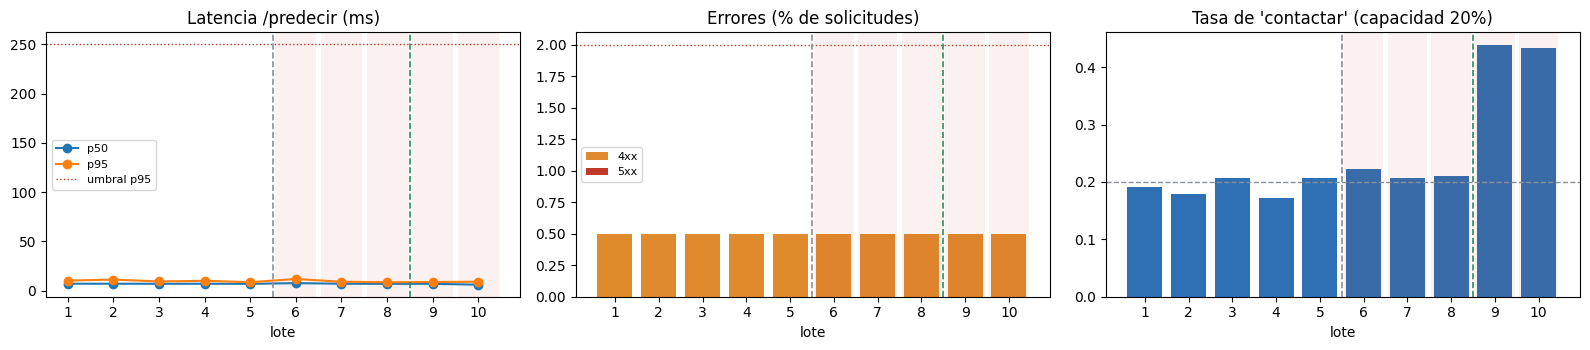

In [5]:
ree_ok = ree[ree.decision.str.startswith('aprobado')] if len(ree) else ree
def marcas(ax):
    for l in sorted(ale[ale.severidad == 'Alta'].lote_id.unique()):
        ax.axvspan(l - .45, l + .45, color=ROJO, alpha=.07, lw=0)
    for _, r in ree.iterrows():
        ax.axvline(r.lote_disparo + .5, color=VERDE if str(r.decision).startswith('aprobado') else GRIS, ls='--', lw=1.2)
    ax.set_xticks(range(1, int(mon.lote_id.max()) + 1))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].plot(sis.index, sis.latencia_p50_ms, 'o-', label='p50'); ax[0].plot(sis.index, sis.latencia_p95_ms, 'o-', label='p95')
ax[0].axhline(250, color=ROJO, ls=':', lw=1, label='umbral p95'); ax[0].set_title('Latencia /predecir (ms)'); ax[0].legend(fontsize=8)
ax[1].bar(sis.index, sis.tasa_4xx * 100, color=NARANJA, label='4xx'); ax[1].bar(sis.index, sis.tasa_5xx * 100, bottom=sis.tasa_4xx * 100, color=ROJO, label='5xx')
ax[1].axhline(2, color=ROJO, ls=':', lw=1); ax[1].set_title('Errores (% de solicitudes)'); ax[1].legend(fontsize=8)
ax[2].bar(mod.index, mod.tasa_contactar, color=AZUL); ax[2].axhline(.20, color=GRIS, ls='--', lw=1); ax[2].set_title("Tasa de 'contactar' (capacidad 20%)")
for a in ax: marcas(a); a.set_xlabel('lote')
plt.tight_layout(); plt.savefig('../docs/img/monitoreo_sistema_modelo.png', dpi=130); plt.show()

## 4. Deriva de datos y deriva conceptual

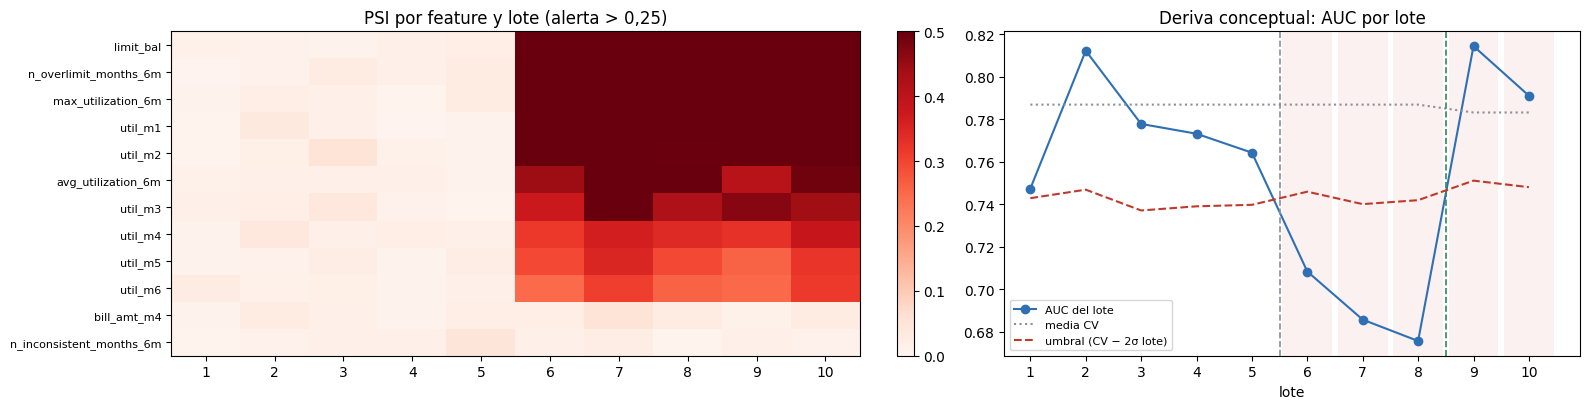

In [6]:
psi = mon[(mon.tipo == 'deriva') & (mon.metrica == 'psi')].pivot_table(index='feature', columns='lote_id', values='valor', aggfunc='last')
top = psi.loc[psi.max(axis=1).sort_values(ascending=False).index[:12]]
fig, ax = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={'width_ratios': [1.3, 1]})
im = ax[0].imshow(top.values, aspect='auto', cmap='Reds', vmin=0, vmax=.5)
ax[0].set_yticks(range(len(top))); ax[0].set_yticklabels(top.index, fontsize=8); ax[0].set_xticks(range(top.shape[1])); ax[0].set_xticklabels(top.columns)
ax[0].set_title('PSI por feature y lote (alerta > 0,25)'); plt.colorbar(im, ax=ax[0], fraction=.03)
dz = pd.DataFrame({m: serie('desempeno', m) for m in ['auc', 'umbral_auc', 'cv_mean', 'version_modelo', 'ahorro_modelo', 'ahorro_regla',
                                                      'ahorro_modelo_igual_volumen', 'tasa_impago_real', 'contactados', 'moras_detectadas']})
ax[1].plot(dz.index, dz.auc, 'o-', color=AZUL, label='AUC del lote'); ax[1].plot(dz.index, dz.cv_mean, ':', color=GRIS, label='media CV')
ax[1].plot(dz.index, dz.umbral_auc, '--', color=ROJO, label='umbral (CV − 2σ lote)'); marcas(ax[1]); ax[1].legend(fontsize=8)
ax[1].set_title('Deriva conceptual: AUC por lote'); ax[1].set_xlabel('lote')
plt.tight_layout(); plt.savefig('../docs/img/monitoreo_deriva.png', dpi=130); plt.show()

In [7]:
diag = mon[mon.tipo == 'diagnostico'][['lote_id', 'metrica']].rename(columns={'metrica': 'diagnostico'}).set_index('lote_id').sort_index()
acciones = {'estable': 'Ninguna', 'deriva_datos_sin_impacto': 'No reentrenar; actualizar la referencia de entrenamiento y vigilar',
            'deriva_datos_con_impacto': 'Reentrenar con los lotes recientes (con aprobación) y revisar la fuente',
            'deriva_conceptual': 'Reentrenar con los lotes recientes; si no mejora, revisar features y la regla de negocio'}
diag['psi_max_del_lote'] = psi_max.reindex(diag.index).round(3)
diag['auc'] = dz.auc.reindex(diag.index).round(3); diag['umbral'] = dz.umbral_auc.reindex(diag.index).round(3)
diag['version'] = dz.version_modelo.reindex(diag.index); diag['accion'] = diag.diagnostico.map(acciones)
diag

,diagnostico,psi_max_del_lote,auc,umbral,version,accion
lote_id,,,,,,
1,estable,0.029,0.747,0.743,1.0,Ninguna
2,estable,0.039,0.812,0.747,1.0,Ninguna
3,estable,0.051,0.778,0.737,1.0,Ninguna
4,estable,0.028,0.773,0.739,1.0,Ninguna
5,estable,0.047,0.764,0.740,1.0,Ninguna
6,deriva_datos_con_impacto,0.902,0.708,0.746,1.0,Reentrenar con los lotes recientes (con aproba...
7,deriva_datos_con_impacto,1.099,0.686,0.740,1.0,Reentrenar con los lotes recientes (con aproba...
8,deriva_datos_con_impacto,0.921,0.676,0.742,1.0,Reentrenar con los lotes recientes (con aproba...
9,deriva_datos_sin_impacto,0.932,0.815,0.751,4.0,No reentrenar; actualizar la referencia de ent...


In [8]:
lim = sim.INICIO_DERIVA
a = ale.copy(); a['lote_con_deriva'] = a.lote_id >= lim
cruce = a.pivot_table(index='regla', columns='lote_con_deriva', values='lote_id', aggfunc='nunique', fill_value=0)
cruce.columns = [f'lotes {"con" if c else "sin"} deriva' for c in cruce.columns]
falsas = a[(~a.lote_con_deriva) & a.regla.isin(['deriva_datos_feature', 'deriva_datos_moderada', 'concepto_auc', 'deriva_score'])]
print('Falsas alarmas de deriva (lotes 1-5):', len(falsas)); display(falsas[['lote_id', 'regla', 'mensaje']]) if len(falsas) else None
cruce

Falsas alarmas de deriva (lotes 1-5): 0


,lotes con deriva
regla,
capacidad_excedida,2
concepto_auc,3
deriva_datos_feature,5
deriva_score,2


## 5. Reentrenamientos: disparo, comparación y decisión

In [9]:
cols = ['lote_disparo', 'motivo', 'lote_evaluacion', 'version_champion_previo', 'version_challenger', 'auc_champion', 'auc_challenger',
        'ahorro_champion', 'ahorro_challenger', 'delta_ahorro', 'sigma_cv_ahorro', 'cumple_regla', 'viol_comportamiento', 'decision', 'comentario']
ree[[c for c in cols if c in ree]].round(3)

,lote_disparo,motivo,lote_evaluacion,version_champion_previo,version_challenger,auc_champion,auc_challenger,ahorro_champion,ahorro_challenger,delta_ahorro,sigma_cv_ahorro,cumple_regla,viol_comportamiento,decision,comentario
0,5,calendario,4,1,3,0.773,0.765,887268.643,844233.704,-43034.938,14442.160,0,0,rechazado,No supera al champion: diferencia de ahorro -4...
1,8,desempeno,7,1,4,0.686,0.750,1035479.240,1064678.686,29199.446,14785.248,1,76,aprobado,Aprobado: cumple la regla (+29.199 vs sigma_CV...


## 6. Resultado de negocio lote por lote (sección 9)

Se comparan tres alternativas, con la fórmula de pérdida evitada neta del PSet 1 (`saldo medio en riesgo × 30 % de éxito − NT$ 500 por llamada`):
- **Modelo.** Llama a los clientes cuya probabilidad supera el corte, hasta la capacidad del 20 % del lote.
- **Regla actual.** Llama a todo cliente con 1 mes de atraso o más.
- **No hacer nada.** Ahorro de 0 por definición.

**Efecto del reentrenamiento.** Los lotes posteriores a la promoción se vuelven a puntuar, fuera de línea, con el champion anterior. La diferencia entre los dos ahorros es lo que aportó reentrenar.

In [10]:
neg = dz[['version_modelo', 'tasa_impago_real', 'contactados', 'moras_detectadas', 'ahorro_modelo', 'ahorro_regla']].copy()
neg['ahorro_nada'] = 0.0; neg['modelo_menos_regla'] = neg.ahorro_modelo - neg.ahorro_regla
neg['ahorro_sin_reentrenar'] = np.nan
if len(ree_ok):
    r = ree_ok.iloc[0]; prev = int(r.version_champion_previo); nuevo = int(r.version_challenger)
    viejo = mlflow.sklearn.load_model(f'models:/{MODELO_REGISTRO}/{prev}')
    from api.esquemas import FEATURES as feats
    for l in neg.index[neg.version_modelo == nuevo]:
        d = des[(des.lote_id == l) & (des.fuente == 'modelo')].merge(lotes[[ID, 'lote_id'] + feats].rename(columns={ID: 'customer_id'}), on=['customer_id', 'lote_id'])
        s = viejo.predict_proba(d[feats])[:, 1]; corte = max(float(c.get_run(c.get_model_version(MODELO_REGISTRO, str(prev)).run_id).data.params['corte_efectivo_train_oof']), .05)
        neg.loc[l, 'ahorro_sin_reentrenar'] = negocio.ahorro(d.target, (s >= corte) & negocio.contactar_top(s, 0.0), float(r.get('saldo', negocio.SALDO_MEDIO)) if 'saldo' in r else negocio.SALDO_MEDIO)
neg['efecto_reentrenar'] = neg.ahorro_modelo - neg.ahorro_sin_reentrenar
neg.to_csv('../docs/negocio_por_lote.csv')
neg.round(0)

,version_modelo,tasa_impago_real,contactados,moras_detectadas,ahorro_modelo,ahorro_regla,ahorro_nada,modelo_menos_regla,ahorro_sin_reentrenar,efecto_reentrenar
lote_id,,,,,,,,,,
1,1.0,0.0,114.0,58.0,777622.0,731952.0,0.0,45670.0,NaN,NaN
2,1.0,0.0,107.0,64.0,867463.0,943803.0,0.0,-76340.0,NaN,NaN
3,1.0,0.0,119.0,67.0,904633.0,882243.0,0.0,22390.0,NaN,NaN
4,1.0,0.0,103.0,58.0,783122.0,788013.0,0.0,-4890.0,NaN,NaN
5,1.0,0.0,119.0,68.0,919023.0,785013.0,0.0,134010.0,NaN,NaN
6,1.0,0.0,119.0,70.0,947803.0,920413.0,0.0,27390.0,NaN,NaN
7,1.0,0.0,119.0,75.0,1019753.0,972583.0,0.0,47170.0,NaN,NaN
8,1.0,0.0,119.0,72.0,976583.0,856463.0,0.0,120120.0,NaN,NaN
9,4.0,0.0,119.0,91.0,1269075.0,989780.0,0.0,279295.0,919023.0,350052.0


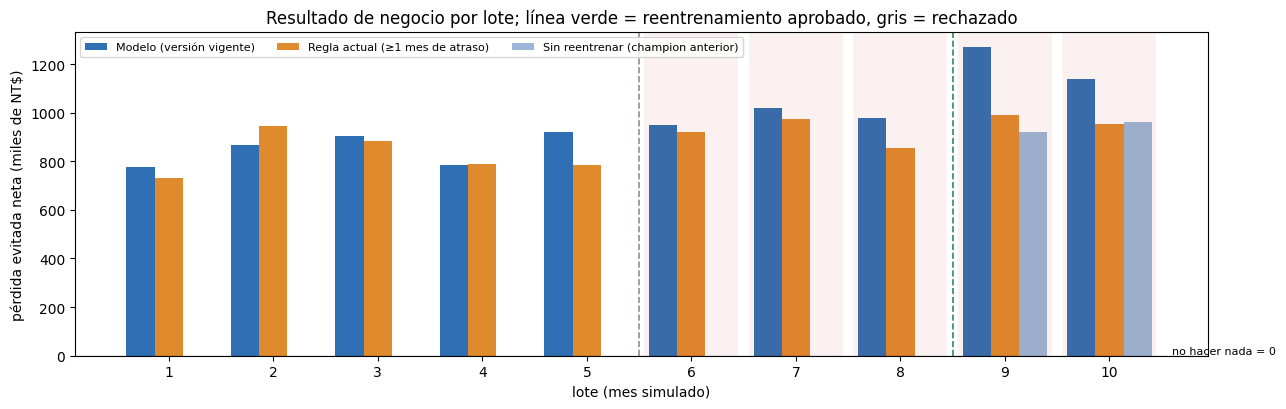

Total 10 lotes: modelo NT$ 9,602,755 | regla NT$ 8,825,242 | nada NT$ 0 | extra vs regla NT$ 777,512 (8.8%); el modelo gana a la regla en 8 de 10 lotes


In [11]:
fig, ax = plt.subplots(figsize=(13, 4.2)); x = neg.index.values; w = .27
ax.bar(x - w, neg.ahorro_modelo / 1e3, w, color=AZUL, label='Modelo (versión vigente)')
ax.bar(x, neg.ahorro_regla / 1e3, w, color=NARANJA, label='Regla actual (≥1 mes de atraso)')
ax.bar(x + w, neg.ahorro_sin_reentrenar.fillna(0) / 1e3, w, color='#9bb7d9', label='Sin reentrenar (champion anterior)')
ax.axhline(0, color='k', lw=.8); ax.text(x.max() + .6, 0, 'no hacer nada = 0', va='bottom', fontsize=8)
marcas(ax); ax.set_xlabel('lote (mes simulado)'); ax.set_ylabel('pérdida evitada neta (miles de NT$)')
ax.set_title('Resultado de negocio por lote; línea verde = reentrenamiento aprobado, gris = rechazado'); ax.legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.savefig('../docs/img/negocio_por_lote.png', dpi=130); plt.show()
tot = neg[['ahorro_modelo', 'ahorro_regla', 'ahorro_nada']].sum()
print(f"Total {len(neg)} lotes: modelo NT$ {tot.ahorro_modelo:,.0f} | regla NT$ {tot.ahorro_regla:,.0f} | nada NT$ 0 | "
      f"extra vs regla NT$ {tot.ahorro_modelo - tot.ahorro_regla:,.0f} ({(tot.ahorro_modelo/tot.ahorro_regla - 1):.1%}); "
      f"el modelo gana a la regla en {(neg.modelo_menos_regla > 0).sum()} de {len(neg)} lotes")

## 7. Ética operativa (sección 8)

**7.1 Desempeño por subgrupo.** Los subgrupos se definen por **edad** y por **nivel de educación**. Son las variables de la persona que el modelo sí usa; sexo y estado civil se excluyeron desde el PSet 1. Se agrega el **tamaño del cupo**, que separa a clientes de menores ingresos.

Para cada subgrupo se calcula:
- AUC.
- Tasa de contacto.
- *Recall*: qué parte de los morosos reales recibió la llamada preventiva.
- Precisión.

Se usan todas las predicciones etiquetadas del modelo durante la simulación.

In [12]:
d = des[des.fuente == 'modelo'].merge(lotes[[ID, 'lote_id', 'age', 'education_code', 'limit_bal']].rename(columns={ID: 'customer_id'}), on=['customer_id', 'lote_id'])
d['contactado'] = (d.decision == 'contactar')
d['grupo_edad'] = pd.cut(d.age, [0, 29, 45, 120], labels=['<30', '30-45', '>45'])
d['educacion'] = d.education_code.map({1: 'posgrado', 2: 'universidad', 3: 'secundaria', 4: 'otros'})
d['cupo'] = pd.qcut(d.limit_bal, 3, labels=['cupo bajo', 'cupo medio', 'cupo alto'])
def met(g):
    y, s, c = g.target.astype(int), g.probabilidad, g.contactado
    return pd.Series({'n': len(g), 'tasa_impago': y.mean(), 'tasa_contacto': c.mean(), 'auc': roc_auc_score(y, s) if y.nunique() > 1 else np.nan,
                      'recall': (c & (y == 1)).sum() / max((y == 1).sum(), 1), 'precision': (c & (y == 1)).sum() / max(c.sum(), 1),
                      'falsos_positivos': int((c & (y == 0)).sum()), 'falsos_negativos': int((~c & (y == 1)).sum())})
sub = pd.concat({v: d.groupby(v).apply(met) for v in ['grupo_edad', 'educacion', 'cupo']}).round(3)
sub.index.names = ['variable', 'grupo']; sub.to_csv('../docs/subgrupos.csv'); sub

n  tasa_impago  tasa_contacto    auc  recall  \
variable   grupo                                                            
grupo_edad <30          1904.0        0.316          0.262  0.750   0.493   
           30-45        3108.0        0.292          0.224  0.765   0.458   
           >45           958.0        0.341          0.293  0.774   0.523   
educacion  otros          82.0        0.171          0.098  0.732   0.143   
           posgrado     2119.0        0.260          0.186  0.777   0.429   
           secundaria   1008.0        0.341          0.293  0.720   0.497   
           universidad  2761.0        0.336          0.282  0.758   0.511   
cupo       cupo bajo    2120.0        0.432          0.422  0.697   0.584   
           cupo medio   1861.0        0.285          0.192  0.738   0.394   
           cupo alto    1989.0        0.196          0.113  0.779   0.356   

                        precision  falsos_positivos  falsos_negativos  
variable   grupo                                                       
grupo_edad <30              0.593             203.0             305.0  
           30-45            0.598             280.0             492.0  
           >45              0.609             110.0             156.0  
educacion  otros            0.250               6.0              12.0  
           posgrado         0.599             158.0             314.0  
           secundaria       0.580             124.0             173.0  
           universidad      0.608             305.0             454.0  
cupo       cupo bajo        0.598             359.0             381.0  
           cupo medio       0.585             148.0             321.0  
           cupo alto        0.618              86.0             251.0

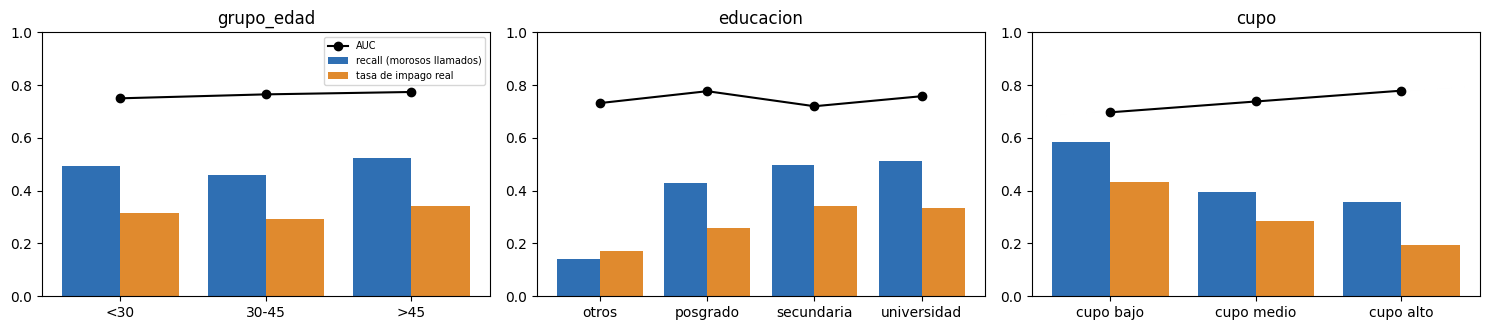

Brecha de recall entre grupos: {'grupo_edad': 0.065, 'educacion': 0.368, 'cupo': 0.228} | brecha de AUC: {'grupo_edad': 0.024, 'educacion': 0.057, 'cupo': 0.082}


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for a, v in zip(ax, ['grupo_edad', 'educacion', 'cupo']):
    s = sub.loc[v]; x = np.arange(len(s))
    a.bar(x - .2, s.recall, .4, label='recall (morosos llamados)', color=AZUL); a.bar(x + .2, s.tasa_impago, .4, label='tasa de impago real', color=NARANJA)
    a.plot(x, s.auc, 'ko-', label='AUC'); a.set_xticks(x); a.set_xticklabels(s.index); a.set_ylim(0, 1); a.set_title(v)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig('../docs/img/subgrupos.png', dpi=130); plt.show()
brecha = {v: float(sub.loc[v].recall.max() - sub.loc[v].recall.min()) for v in ['grupo_edad', 'educacion', 'cupo']}
brecha_auc = {v: float(sub.loc[v].auc.max() - sub.loc[v].auc.min()) for v in ['grupo_edad', 'educacion', 'cupo']}
print('Brecha de recall entre grupos:', {k: round(v, 3) for k, v in brecha.items()}, '| brecha de AUC:', {k: round(v, 3) for k, v in brecha_auc.items()})

**7.2 Costo de cada error**, medido en las predicciones etiquetadas de la simulación:

In [14]:
fp = int((d.contactado & (d.target == 0)).sum()); fn = int((~d.contactado & (d.target == 1)).sum())
costo = pd.DataFrame([
    {'error': 'Falso positivo', 'que_pasa': 'se llama a un cliente que sí iba a pagar', 'casos': fp,
     'costo_estimado_NT': fp * negocio.C_CONTACTO, 'quien_lo_asume': 'Área de cobranza (tiempo del asesor) y el cliente (una llamada de cobranza que no necesitaba)'},
    {'error': 'Falso negativo', 'que_pasa': 'no se llama a un cliente que no paga', 'casos': fn,
     'costo_estimado_NT': fn * negocio.SALDO_MEDIO * negocio.T_EXITO, 'quien_lo_asume': 'Banco (provisión y pérdida de la deuda; riesgo de crédito) y el cliente (cae en mora: intereses y buró)'}])
costo

,error,que_pasa,casos,costo_estimado_NT,quien_lo_asume
0,Falso positivo,se llama a un cliente que sí iba a pagar,593,2.965000e+05,Área de cobranza (tiempo del asesor) y el clie...
1,Falso negativo,no se llama a un cliente que no paga,953,1.371371e+07,Banco (provisión y pérdida de la deuda; riesgo...


**7.3 Criterios de retirada.** Se evalúan con los datos de la simulación:

In [15]:
post = dz.join(neg[['modelo_menos_regla']]); post = post[post.version_modelo == post.version_modelo.iloc[-1]] if len(ree_ok) else post
criterios = pd.DataFrame([
    {'condicion': 'Ahorro del modelo < ahorro de la regla 2 lotes seguidos, AUN DESPUÉS de reentrenar', 'metrica': 'ahorro por lote',
     'umbral': '2 lotes', 'respuesta': 'Interruptor de respaldo: la API sirve la regla; revisión del modelo',
     'estado_simulacion': 'no se cumple' if not (post.modelo_menos_regla < 0).rolling(2).sum().ge(2).any() else 'SE CUMPLE'},
    {'condicion': 'AUC < 0,70 en 2 lotes seguidos después de un reentrenamiento aprobado', 'metrica': 'AUC del lote', 'umbral': '0,70 (≈ regla de negocio)',
     'respuesta': 'Retirar el modelo: respaldo + nuevo ciclo de features', 'estado_simulacion': 'no se cumple' if not (post.auc < .70).rolling(2).sum().ge(2).any() else 'SE CUMPLE'},
    {'condicion': 'Errores 5xx > 5% o el modelo no carga', 'metrica': 'tasa_5xx / /salud', 'umbral': '5% en 1 lote',
     'respuesta': 'Respaldo automático (la API ya lo hace si el modelo no carga) y escalar a plataforma', 'estado_simulacion': 'no se cumple' if sis.tasa_5xx.max() <= .05 else 'SE CUMPLE'},
    {'condicion': 'Brecha de recall entre grupos de edad o de cupo > 0,15', 'metrica': 'recall por subgrupo', 'umbral': '0,15',
     'respuesta': 'Ajustar: corte por segmento o revisión de features; la decisión vuelve a ser 100% humana en ese segmento',
     'estado_simulacion': 'no se cumple' if max(brecha['grupo_edad'], brecha['cupo']) <= .15 else 'SE CUMPLE'},
    {'condicion': 'Tasa de contacto > 25% (más que la capacidad) 2 lotes seguidos', 'metrica': 'tasa_contactar', 'umbral': '25%',
     'respuesta': 'Ajustar: recalibrar el corte con el último lote (la lista se recorta al top 20%)',
     'estado_simulacion': 'SE CUMPLE' if (mod.tasa_contactar > .25).rolling(2).sum().ge(2).any() else 'no se cumple'}])
criterios

,condicion,metrica,umbral,respuesta,estado_simulacion
0,Ahorro del modelo < ahorro de la regla 2 lotes...,ahorro por lote,2 lotes,Interruptor de respaldo: la API sirve la regla...,no se cumple
1,"AUC < 0,70 en 2 lotes seguidos después de un r...",AUC del lote,"0,70 (≈ regla de negocio)",Retirar el modelo: respaldo + nuevo ciclo de f...,no se cumple
2,Errores 5xx > 5% o el modelo no carga,tasa_5xx / /salud,5% en 1 lote,Respaldo automático (la API ya lo hace si el m...,no se cumple
3,Brecha de recall entre grupos de edad o de cup...,recall por subgrupo,"0,15",Ajustar: corte por segmento o revisión de feat...,SE CUMPLE
4,Tasa de contacto > 25% (más que la capacidad) ...,tasa_contactar,25%,Ajustar: recalibrar el corte con el último lot...,SE CUMPLE


**7.4 Evidencia del rollback y del interruptor de respaldo**, generada con `python scripts/evidencia_operacion.py` contra la API en Docker:

In [16]:
ev = json.load(open('../docs/evidencia_operacion.json')) if os.path.exists('../docs/evidencia_operacion.json') else []
pd.DataFrame([{'paso': e['paso'], 'version_en_/modelo': e['modelo']['version'], 'fuente_activa': e['modelo']['fuente_activa'],
               'probabilidad': e['prediccion']['probabilidad'], 'decision': e['prediccion']['decision'],
               'version_en_/predecir': e['prediccion']['version_modelo'], 'respaldo': e['prediccion']['respaldo']} for e in ev])

,paso,version_en_/modelo,fuente_activa,probabilidad,decision,version_en_/predecir,respaldo
0,1. champion vigente,4,modelo,0.669047,contactar,4.0,False
1,2. rollback: alias -> v1 (sin rebuild),1,modelo,0.691213,contactar,1.0,False
2,3. restitución: alias -> v4,4,modelo,0.669047,contactar,4.0,False
3,4. interruptor de respaldo ENCENDIDO,4,regla_negocio,0.504000,contactar,NaN,True
4,5. interruptor de respaldo APAGADO,4,modelo,0.669047,contactar,4.0,False


## 8. Resumen para el documento técnico y la presentación

In [17]:
prim = ale[ale.regla == 'deriva_datos_feature'].lote_id.min() if len(ale) else None
resumen = {
  'n_lotes': int(neg.index.max()), 'clientes_por_lote': int(lotes.groupby('lote_id').size().median()), 'inicio_deriva': lim,
  'predicciones': int(len(pred)), 'rechazos_4xx': int((tabla_lotes.tasa_4xx * tabla_lotes.volumen_solicitudes).sum()),
  'latencia_p50_ms': float(sis.latencia_p50_ms.median()), 'latencia_p95_ms_max': float(sis.latencia_p95_ms.max()),
  'tasa_5xx_max': float(sis.tasa_5xx.max()), 'alertas': int(len(ale)), 'alertas_altas': int((ale.severidad == 'Alta').sum()),
  'primer_lote_alerta_deriva': None if prim is None or pd.isna(prim) else int(prim), 'falsas_alarmas_deriva': int(len(falsas)),
  'falsas_alarmas_detalle': falsas[['lote_id', 'regla', 'mensaje']].to_dict('records'),
  'psi_max_lotes_limpios': float(psi_max[psi_max.index < lim].max()), 'psi_max_lotes_deriva': float(psi_max[psi_max.index >= lim].max()),
  'piso_ruido_psi_p99_max': float(pd.read_csv('../docs/piso_ruido_psi.csv').psi_p99.max()) if os.path.exists('../docs/piso_ruido_psi.csv') else None,
  'reentrenamientos': ree[[c for c in cols if c in ree]].to_dict('records'),
  'negocio': {'modelo': float(tot.ahorro_modelo), 'regla': float(tot.ahorro_regla), 'nada': 0.0,
              'extra_vs_regla': float(tot.ahorro_modelo - tot.ahorro_regla), 'lotes_modelo_gana': int((neg.modelo_menos_regla > 0).sum()),
              'efecto_reentrenar': float(neg.efecto_reentrenar.sum(skipna=True)), 'lotes_post_reentreno': neg.index[neg.efecto_reentrenar.notna()].tolist(),
              'por_lote': neg.reset_index().round(2).to_dict('records')},
  'diagnostico': diag.reset_index().to_dict('records'),
  'subgrupos_brecha_recall': brecha, 'subgrupos_brecha_auc': brecha_auc, 'costo_errores': costo.to_dict('records'),
  'criterios_retirada': criterios.to_dict('records'), 'traza': traza,
  'auc_por_lote': dz.auc.round(4).to_dict(), 'umbral_auc_por_lote': dz.umbral_auc.round(4).to_dict(),
  'tasa_contactar_por_lote': mod.tasa_contactar.round(4).to_dict(),
}
json.dump(resumen, open('../docs/resumen_simulacion.json', 'w'), indent=2, ensure_ascii=False, default=str)
{k: resumen[k] for k in ['alertas', 'alertas_altas', 'primer_lote_alerta_deriva', 'falsas_alarmas_deriva', 'psi_max_lotes_limpios', 'psi_max_lotes_deriva']} | {'negocio': {k: v for k, v in resumen['negocio'].items() if k != 'por_lote'}}

{'alertas': 12,
 'alertas_altas': 8,
 'primer_lote_alerta_deriva': 6,
 'falsas_alarmas_deriva': 0,
 'psi_max_lotes_limpios': 0.0508709879916399,
 'psi_max_lotes_deriva': 1.2206899404288598,
 'negocio': {'modelo': 9602754.782,
  'regla': 8825242.348,
  'nada': 0.0,
  'extra_vs_regla': 777512.4340000004,
  'lotes_modelo_gana': 8,
  'efecto_reentrenar': 525535.9289999999,
  'lotes_post_reentreno': [9, 10]}}